# Section 4 — Higher-Order Taylor Methods

[← Euler Error](03_euler_error.ipynb) ·
[Module 3](README.md) ·
[Next: RK2 and RK3 →](05_rk2_rk3.ipynb)

Euler keeps only the first derivative term in the Taylor expansion. Keeping
additional terms gives higher-order Taylor methods:

$$
y(t+h)
=
y(t)
+h y'(t)
+\frac{h^2}{2}y''(t)
+\frac{h^3}{6}y^{(3)}(t)
+\frac{h^4}{24}y^{(4)}(t)
+\cdots.
$$

### Learning goals

- construct Taylor methods of orders 2, 3, and 4;
- compute a local truncation error for Taylor order 2;
- implement the methods;
- compare their accuracy;
- verify numerical convergence order;
- understand why Runge-Kutta methods avoid repeated symbolic differentiation.


In [1]:
import numpy as np
import matplotlib.pyplot as plt


## 1. Use the course IVP

Consider

$$
y'=t e^{3t}-2y,
\qquad
y(0)=0.
$$

The exact solution is

$$
y(t)
=
e^{3t}
\left(
\frac{t}{5}-\frac1{25}
\right)
+
\frac1{25}e^{-2t}.
$$

Successive derivatives are

$$
y''=e^{3t}(1+t)+4y,
$$

$$
y^{(3)}=e^{3t}(4+7t)-8y,
$$

and

$$
y^{(4)}=e^{3t}(19+13t)+16y.
$$


In [2]:
def y1(t, y):
    return t * np.exp(3.0 * t) - 2.0 * y


def y2(t, y):
    return (
        np.exp(3.0 * t) * (1.0 + t)
        + 4.0 * y
    )


def y3(t, y):
    return (
        np.exp(3.0 * t) * (4.0 + 7.0 * t)
        - 8.0 * y
    )


def y4(t, y):
    return (
        np.exp(3.0 * t) * (19.0 + 13.0 * t)
        + 16.0 * y
    )


def exact(t):
    return (
        np.exp(3.0 * t)
        * (t / 5.0 - 1.0 / 25.0)
        + np.exp(-2.0 * t) / 25.0
    )


## 2. Taylor methods of orders 2, 3, and 4

The second-order method is

$$
w_{n+1}
=
w_n
+h y'(t_n,w_n)
+\frac{h^2}{2}y''(t_n,w_n).
$$

Order 3 adds

$$
\frac{h^3}{6}y^{(3)}(t_n,w_n),
$$

and order 4 adds

$$
\frac{h^4}{24}y^{(4)}(t_n,w_n).
$$


In [3]:
def taylor2(t0, y0, h, n_steps):
    t = np.empty(n_steps + 1)
    w = np.empty(n_steps + 1)
    t[0], w[0] = t0, y0

    for n in range(n_steps):
        w[n + 1] = (
            w[n]
            + h * y1(t[n], w[n])
            + h**2 * y2(t[n], w[n]) / 2.0
        )
        t[n + 1] = t[n] + h

    return t, w


def taylor3(t0, y0, h, n_steps):
    t = np.empty(n_steps + 1)
    w = np.empty(n_steps + 1)
    t[0], w[0] = t0, y0

    for n in range(n_steps):
        w[n + 1] = (
            w[n]
            + h * y1(t[n], w[n])
            + h**2 * y2(t[n], w[n]) / 2.0
            + h**3 * y3(t[n], w[n]) / 6.0
        )
        t[n + 1] = t[n] + h

    return t, w


def taylor4(t0, y0, h, n_steps):
    t = np.empty(n_steps + 1)
    w = np.empty(n_steps + 1)
    t[0], w[0] = t0, y0

    for n in range(n_steps):
        w[n + 1] = (
            w[n]
            + h * y1(t[n], w[n])
            + h**2 * y2(t[n], w[n]) / 2.0
            + h**3 * y3(t[n], w[n]) / 6.0
            + h**4 * y4(t[n], w[n]) / 24.0
        )
        t[n + 1] = t[n] + h

    return t, w


## 3. Local truncation error for Taylor order 2

If the Taylor-2 method starts a step from the **exact** value $y(t_n)$, then

$$
y(t_{n+1})
=
y(t_n)
+h y'(t_n)
+\frac{h^2}{2}y''(t_n)
+\frac{h^3}{6}y^{(3)}(\xi_n).
$$

The Taylor-2 update omits the last term.

Thus the one-step defect is

$$
d_{n+1}
=
\frac{h^3}{6}y^{(3)}(\xi_n)
=
O(h^3).
$$

If local truncation error is defined after dividing by $h$, then

$$
\tau_{n+1}
=
\frac{d_{n+1}}{h}
=
O(h^2).
$$

The code below computes the **actual one-step defect** using the exact solution.


In [4]:
def taylor2_one_step_from_exact(t_value, h):
    y_value = exact(t_value)
    return (
        y_value
        + h * y1(t_value, y_value)
        + h**2 * y2(
            t_value,
            y_value,
        ) / 2.0
    )


h = 0.5

for t_value in [0.0, 0.5]:
    predicted = taylor2_one_step_from_exact(
        t_value,
        h,
    )
    exact_next = exact(t_value + h)
    defect = exact_next - predicted
    scaled_lte = defect / h

    print(f"step starting at t={t_value:.1f}")
    print(f"  one-step defect = {defect:.8e}")
    print(f"  scaled LTE      = {scaled_lte:.8e}")


step starting at t=0.0
  one-step defect = 1.58616522e-01
  scaled LTE      = 3.17233044e-01
step starting at t=0.5
  one-step defect = 1.11655209e+00
  scaled LTE      = 2.23310418e+00


## 4. Compare orders 2, 3, and 4

Use $h=0.5$, so two steps move from $t=0$ to $t=1$.


In [5]:
h = 0.5
n_steps = 2

methods = {
    "Taylor 2": taylor2,
    "Taylor 3": taylor3,
    "Taylor 4": taylor4,
}

print(
    "method        approximation      "
    "exact y(1)        error"
)

for name, method in methods.items():
    _, w = method(
        0.0,
        0.0,
        h,
        n_steps,
    )
    error = abs(exact(1.0) - w[-1])
    print(
        f"{name:10s}   {w[-1]:12.8f}   "
        f"{exact(1.0):12.8f}   {error:10.6f}"
    )


method        approximation      exact y(1)        error
Taylor 2       2.02323897     3.21909932     1.195860
Taylor 3       2.73044733     3.21909932     0.488652
Taylor 4       3.05529474     3.21909932     0.163805


## 5. Verify convergence order

If the global error satisfies

$$
E(h)\approx C h^p,
$$

then halving $h$ should reduce the error by approximately $2^p$.


In [6]:
step_sizes = np.array(
    [0.5, 0.25, 0.125, 0.0625]
)

results = {
    name: []
    for name in methods
}

for h in step_sizes:
    n_steps = round(1.0 / h)

    for name, method in methods.items():
        _, w = method(
            0.0,
            0.0,
            h,
            n_steps,
        )
        results[name].append(
            abs(exact(1.0) - w[-1])
        )

for name, errors in results.items():
    print(f"\n{name}")
    print("     h          error       observed p")
    previous = None

    for h, error in zip(
        step_sizes,
        errors,
    ):
        if previous is None:
            p_text = "   --"
        else:
            order = (
                np.log(previous / error)
                / np.log(2.0)
            )
            p_text = f"{order:7.4f}"

        print(
            f"{h:7.4f}   "
            f"{error:12.6e}   "
            f"{p_text}"
        )
        previous = error



Taylor 2
     h          error       observed p
 0.5000   1.195860e+00      --
 0.2500   3.482400e-01    1.7799
 0.1250   8.984435e-02    1.9546
 0.0625   2.256518e-02    1.9933

Taylor 3
     h          error       observed p
 0.5000   4.886520e-01      --
 0.2500   7.523294e-02    2.6994
 0.1250   9.969787e-03    2.9157
 0.0625   1.266814e-03    2.9764

Taylor 4
     h          error       observed p
 0.5000   1.638046e-01      --
 0.2500   1.290532e-02    3.6659
 0.1250   8.649885e-04    3.8991
 0.0625   5.527993e-05    3.9679


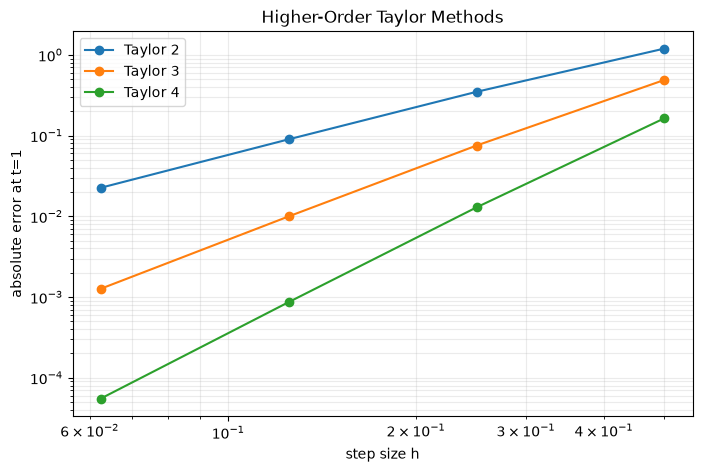

In [7]:
plt.figure(figsize=(8, 5))

for name, errors in results.items():
    plt.loglog(
        step_sizes,
        errors,
        marker="o",
        label=name,
    )

plt.xlabel("step size h")
plt.ylabel("absolute error at t=1")
plt.title("Higher-Order Taylor Methods")
plt.grid(
    True,
    which="both",
    alpha=0.25,
)
plt.legend()
plt.show()


## Why Runge-Kutta?

Higher-order Taylor methods are accurate, but every new order requires another
derivative of the exact solution.

Runge-Kutta methods aim for the same higher-order accuracy using only carefully
chosen evaluations of $f(t,y)$.

### References

- Leon Q. Brin, *Tea Time Numerical Analysis*.
- Richard L. Burden and J. Douglas Faires, *Numerical Analysis*.
- MAD 4401 higher-order Taylor lecture and Exam 3 review.

[Next: RK2 and RK3 →](05_rk2_rk3.ipynb)
